In [1]:
import sys
from pathlib import Path
import random
import matplotlib.pyplot as plt

# Locate the project root
project_root = Path.cwd()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.engine import Value
from src.nn import MLP

random.seed(42)

print("MicroGrad imported successfully!")

MicroGrad imported successfully!


In [2]:
# XOR dataset
X = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0]
]

Y = [-1.0, 1.0, 1.0, -1.0]

print("Dataset:")

for x, y in zip(X, Y):
    print(f"Input: {x}, Target: {y}")

Dataset:
Input: [0.0, 0.0], Target: -1.0
Input: [0.0, 1.0], Target: 1.0
Input: [1.0, 0.0], Target: 1.0
Input: [1.0, 1.0], Target: -1.0


In [3]:
model = MLP(2, [4, 4, 1])

print("Neural Network Created!")
print("Total Parameters:", len(model.parameters()))

Neural Network Created!
Total Parameters: 37


In [4]:
def calculate_loss(model, X, Y):

    predictions = [model(x) for x in X]

    losses = [
        (prediction - target) ** 2
        for prediction, target in zip(predictions, Y)
    ]

    total_loss = sum(losses) / len(losses)

    return total_loss, predictions

In [5]:
epochs = 1000
learning_rate = 0.05

loss_history = []

for epoch in range(epochs):

    # 1. Forward pass and loss calculation
    loss, predictions = calculate_loss(model, X, Y)

    # 2. Reset parameter gradients
    model.zero_grad()

    # 3. Backpropagation
    loss.backward()

    # 4. Update parameters
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    # 5. Store loss
    loss_history.append(loss.data)

    # 6. Display training progress
    if epoch % 100 == 0 or epoch == epochs - 1:
        print(
            f"Epoch {epoch:4d} | "
            f"Loss: {loss.data:.6f}"
        )

Epoch    0 | Loss: 1.877191
Epoch  100 | Loss: 0.127087
Epoch  200 | Loss: 0.033464
Epoch  300 | Loss: 0.017343
Epoch  400 | Loss: 0.011336
Epoch  500 | Loss: 0.008296
Epoch  600 | Loss: 0.006486
Epoch  700 | Loss: 0.005296
Epoch  800 | Loss: 0.004459
Epoch  900 | Loss: 0.003839
Epoch  999 | Loss: 0.003368


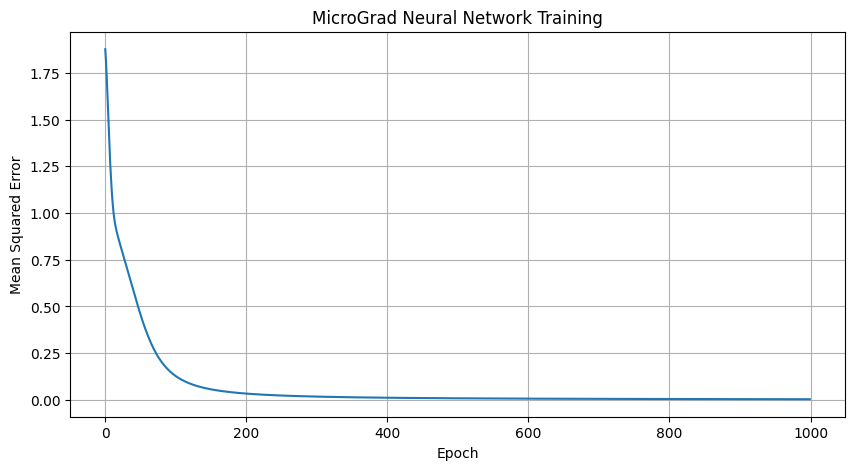

In [6]:
plt.figure(figsize=(10, 5))

plt.plot(loss_history)

plt.title("MicroGrad Neural Network Training")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.show()

In [7]:
print("FINAL MODEL PREDICTIONS")
print("-" * 55)

correct = 0

for x, target in zip(X, Y):

    prediction = model(x).data

    predicted_class = 1 if prediction >= 0 else -1

    if predicted_class == target:
        correct += 1

    print(
        f"Input: {x} | "
        f"Target: {target:+.0f} | "
        f"Prediction: {prediction:+.4f} | "
        f"Class: {predicted_class:+d}"
    )

accuracy = correct / len(Y) * 100

print("-" * 55)
print(f"Training Accuracy: {accuracy:.2f}%")

FINAL MODEL PREDICTIONS
-------------------------------------------------------
Input: [0.0, 0.0] | Target: -1 | Prediction: -0.9520 | Class: -1
Input: [0.0, 1.0] | Target: +1 | Prediction: +0.9325 | Class: +1
Input: [1.0, 0.0] | Target: +1 | Prediction: +0.9371 | Class: +1
Input: [1.0, 1.0] | Target: -1 | Prediction: -0.9486 | Class: -1
-------------------------------------------------------
Training Accuracy: 100.00%
